# Unit 2 — Advanced Visualization & Storytelling (UE24CS342AA9)
## Activity Notebook: Building the Global Development Monitor

### Scenario

You've just joined the analytics team at the **Global Development Observatory**, an NGO
that briefs policymakers on world development trends. Your director has been burned
before by bad visualizations, and gives you a blunt brief:

1. *"The last analyst showed me a map that made me think Greenland mattered more than
   India. Don't let that happen again."*
2. *"We're about to publish a model predicting life expectancy. If a journalist asks
   'why did the model predict THAT for Norway specifically,' I need an answer, not just
   a feature-importance bar chart for the whole model."*
3. *"Every number in our reports is an estimate. I want our numbers to LOOK like
   estimates, not like certainties."*
4. *"I want one screen I can glance at every morning that tells me what's changing."*

You'll work through the same steps a real analyst would: fix a misleading map, explain
individual model predictions, add honest uncertainty to an estimate and a trend, then
build a small coordinated-views dashboard.

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection**
are for you to answer in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the real dataset and real country centroids you'll be
working with.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import plotly.express as px
from sklearn.ensemble import RandomForestRegressor
import shap

# Lightweight fallback for environments without ipywidgets: run each interactive
# callback once with its default values so the notebook remains executable.
try:
    import ipywidgets as widgets
    from ipywidgets import interact, Dropdown
except ImportError:
    class _Widget:
        def __init__(self, **kwargs): self.__dict__.update(kwargs)
    class _Widgets:
        FloatRangeSlider = IntRangeSlider = Dropdown = _Widget
    widgets = _Widgets()
    def interact(func, **kwargs):
        defaults = {k: v.__dict__.get("value", v.__dict__.get("options", [None])[0])
                    for k, v in kwargs.items()}
        return func(**defaults)
    Dropdown = _Widget

np.random.seed(0)

gapminder = px.data.gapminder()
centroids = pd.read_csv("unit2_ppt5_country_centroids_computed.csv")
gap_latest = gapminder[gapminder.year == 2007].merge(centroids, on="iso_alpha", how="left")
gap_latest = gap_latest.assign(total_gdp=gap_latest["pop"] * gap_latest.gdpPercap)

print(f"Loaded {gapminder.country.nunique()} countries, years {sorted(gapminder.year.unique())}.")
gap_latest[["country", "continent", "year", "lifeExp", "pop", "gdpPercap"]].head()

Loaded 142 countries, years [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)].


/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,country,continent,year,lifeExp,pop,gdpPercap
0,Afghanistan,Asia,2007,43.828,31889923,974.580338
1,Albania,Europe,2007,76.423,3600523,5937.029526
2,Algeria,Africa,2007,72.301,33333216,6223.367465
3,Angola,Africa,2007,42.731,12420476,4797.231267
4,Argentina,Americas,2007,75.320,40301927,12779.379640


## Task 1 — Fix the Choropleth Trap (Complaint #1)

**Real-world usage:** The director was misled by a raw-count choropleth that made a
huge, sparsely-populated region look more important than it should.

**Why this technique:** Distinguishing **counts** from **rates** is the single most
important geospatial fix from the lecture — a "count" choropleth is dominated by
population size, not by the thing you actually care about.

**TODO:**
1. Build a choropleth of `total_gdp` (a count-like aggregate) using `px.choropleth`.
2. Build a second choropleth of `gdpPercap` (the rate).
3. Print the top-5 countries by each, and compare.

In [2]:
fig1 = px.choropleth(gap_latest, locations="iso_alpha", color="total_gdp",
                      hover_name="country", title="Total GDP by Country (2007)",
                      color_continuous_scale="Viridis")
fig1.show()
fig2 = px.choropleth(gap_latest, locations="iso_alpha", color="gdpPercap",
                      hover_name="country", title="GDP per Capita by Country (2007)",
                      color_continuous_scale="Plasma")
fig2.show()
top_total = gap_latest.nlargest(5, "total_gdp")[["country", "total_gdp"]].reset_index(drop=True)
top_rate = gap_latest.nlargest(5, "gdpPercap")[["country", "gdpPercap"]].reset_index(drop=True)
print("Top 5 by total GDP:\n", top_total)
print("\nTop 5 by GDP per capita:\n", top_rate)

Top 5 by total GDP:
          country     total_gdp
0  United States  1.293446e+13
1          China  6.539501e+12
2          Japan  4.035135e+12
3          India  2.722925e+12
4        Germany  2.650871e+12

Top 5 by GDP per capita:
          country    gdpPercap
0         Norway  49357.19017
1         Kuwait  47306.98978
2      Singapore  47143.17964
3  United States  42951.65309
4        Ireland  40675.99635


**Reflection:** Which countries appear in one top-5 list but not the other? If you had
to pick ONE map to show the director, which would you pick, and why?

_Your answer:_

## Task 2 — Explain One Specific Prediction (Complaint #2)

**Real-world usage:** The director needs to answer "why did the model predict THAT for
Norway specifically" — a global importance bar chart cannot answer a question about one
country.

**Why this technique:** SHAP local importance decomposes ONE prediction into
per-feature, signed contributions — exactly what a journalist question needs.

**TODO:**
1. Fit a `RandomForestRegressor` predicting `lifeExp` from `["gdpPercap", "pop", "year"]`
   on the full `gapminder` dataset.
2. Build a `shap.TreeExplainer` and compute `shap_values` for all rows.
3. Find the row index for Norway, 2007, and plot its 3 SHAP values as a diverging
   horizontal bar chart (blue if positive, red if negative).

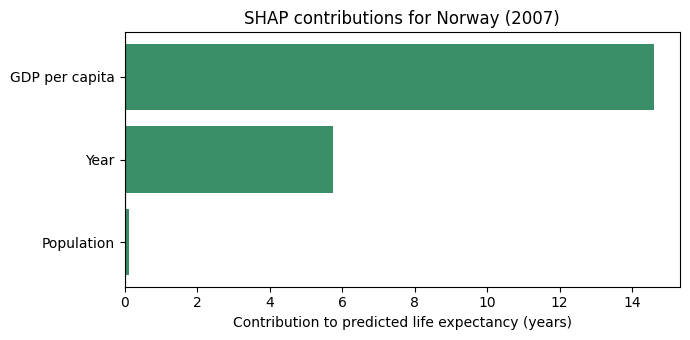

Norway 2007 actual life expectancy: 80.196
Model prediction: 79.93096399999997


In [3]:
X_model = gapminder[["gdpPercap", "pop", "year"]].values
y_model = gapminder["lifeExp"].values
rf = RandomForestRegressor(n_estimators=250, random_state=0, n_jobs=-1)
rf.fit(X_model, y_model)
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_model)
row_idx = gapminder.index[gapminder.country.eq("Norway") & gapminder.year.eq(2007)][0]
vals = np.asarray(shap_values)[row_idx]
fig, ax = plt.subplots(figsize=(7, 3.5))
features = ["GDP per capita", "Population", "Year"]
order = np.argsort(np.abs(vals))
ax.barh(np.array(features)[order], vals[order],
        color=["#b5432e" if v < 0 else "#3b8f68" for v in vals[order]])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("SHAP contributions for Norway (2007)")
ax.set_xlabel("Contribution to predicted life expectancy (years)")
plt.tight_layout()
plt.show()
print("Norway 2007 actual life expectancy:", gapminder.loc[row_idx, "lifeExp"])
print("Model prediction:", rf.predict(X_model[row_idx:row_idx+1])[0])

**Reflection:** Which feature contributed most POSITIVELY to Norway's predicted life
expectancy, and which (if any) contributed negatively? Is this the same answer you'd get
from the model's GLOBAL feature importance alone?

_Your answer:_

## Task 3 — Make an Estimate Look Like an Estimate (Complaint #3)

**Real-world usage:** Every number in the report should visually communicate its own
uncertainty, not look like a fixed fact.

**Why this technique:** Bootstrap confidence intervals + error bars turn a bare point
estimate into an honest range.

**TODO:**
1. Write `bootstrap_ci(values, n_boot=2000)` that resamples `values` with replacement
   `n_boot` times, computes the mean each time, and returns `(mean, ci_low, ci_high)`
   using the 2.5th and 97.5th percentiles of the bootstrap means.
2. Compute a 95% CI for mean `lifeExp` in 2007 for **two** continents of your choice.
3. Plot both as error bars.

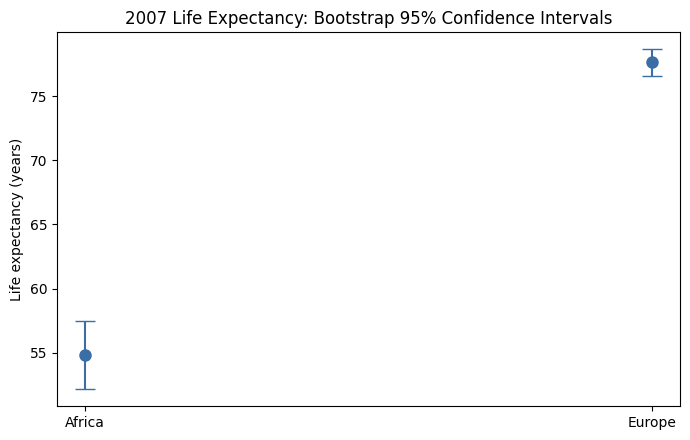

Africa: mean=54.81, 95% CI=(52.15, 57.44)
Europe: mean=77.65, 95% CI=(76.57, 78.65)


In [4]:
def bootstrap_ci(values, n_boot=2000, seed=0):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    samples = rng.choice(values, size=(n_boot, len(values)), replace=True)
    boot_means = samples.mean(axis=1)
    return (float(values.mean()), float(np.percentile(boot_means, 2.5)),
            float(np.percentile(boot_means, 97.5)))
continent_a, continent_b = "Africa", "Europe"
values_a = gap_latest[gap_latest.continent == continent_a].lifeExp.values
values_b = gap_latest[gap_latest.continent == continent_b].lifeExp.values
result_a = bootstrap_ci(values_a)
result_b = bootstrap_ci(values_b)
means = [result_a[0], result_b[0]]
lower = [means[0]-result_a[1], means[1]-result_b[1]]
upper = [result_a[2]-means[0], result_b[2]-means[1]]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar([continent_a, continent_b], means, yerr=[lower, upper],
            fmt="o", capsize=7, markersize=8, color="#3b6ea5")
ax.set_ylabel("Life expectancy (years)")
ax.set_title("2007 Life Expectancy: Bootstrap 95% Confidence Intervals")
plt.tight_layout()
plt.show()
print(f"{continent_a}: mean={result_a[0]:.2f}, 95% CI=({result_a[1]:.2f}, {result_a[2]:.2f})")
print(f"{continent_b}: mean={result_b[0]:.2f}, 95% CI=({result_b[1]:.2f}, {result_b[2]:.2f})")

**Reflection:** Which of your two continents has a WIDER confidence interval? Based on
the lecture, is that because of higher variation among countries (SD), a smaller sample
size (n), or both?

_Your answer:_

## Task 4 — Build the Morning Dashboard (Complaint #4)

**Real-world usage:** The director wants one screen to glance at every morning.

**Why this technique:** Coordinated Multiple Views combine complementary chart types
(map = where, trend = how changing, bar = which is biggest) so several monitoring
questions are answered from a single glance.

**TODO:** Build a 1x3 dashboard:
1. A map-style scatter of country centroids, colored by `lifeExp`.
2. A line chart of world-average `lifeExp` by year (use `gapminder.groupby("year")`).
3. A horizontal bar chart of total population by continent in 2007, sorted.

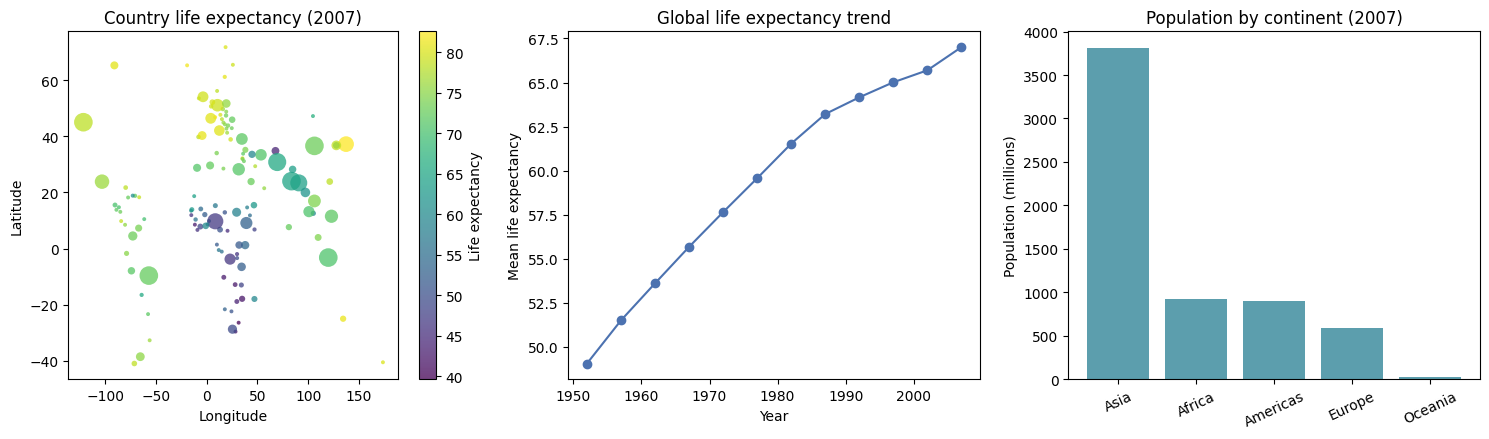

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].scatter(gap_latest["centroid_lon"], gap_latest["centroid_lat"], c=gap_latest["lifeExp"],
                cmap="viridis", s=np.clip(gap_latest["pop"]/1e6, 8, 180),
                alpha=0.75, edgecolor="none")
axes[0].set_title("Country life expectancy (2007)")
axes[0].set_xlabel("Longitude"); axes[0].set_ylabel("Latitude")
sc=axes[0].collections[0]
fig.colorbar(sc, ax=axes[0], label="Life expectancy")
world_trend = gapminder.groupby("year", as_index=False)["lifeExp"].mean()
axes[1].plot(world_trend.year, world_trend.lifeExp, "o-", color="#4C72B0")
axes[1].set_title("Global life expectancy trend")
axes[1].set_xlabel("Year"); axes[1].set_ylabel("Mean life expectancy")
continent_pop = gap_latest.groupby("continent")["pop"].sum().sort_values(ascending=False)
axes[2].bar(continent_pop.index, continent_pop.values/1e6, color="#5c9ead")
axes[2].set_title("Population by continent (2007)")
axes[2].set_ylabel("Population (millions)")
axes[2].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

**Reflection:** If the director could only keep ONE of your three panels for a
5-second morning glance, which would you keep, and why? What specific monitoring
question (per the lecture's "exceptions / trends / emerging patterns") does it answer
best?

_Your answer:_

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence recommendation to your director covering
the whole notebook. Your answer should:
- State which map framing (count vs. rate) you'd standardize on for all future reports,
  and why.
- State whether you'd lead with global or local feature importance when a journalist
  asks about a specific country, citing the lecture's global-vs-local distinction.
- Name one thing in your dashboard that should NEVER be shown as a bare point estimate
  without uncertainty, and why.

_Your final recommendation here:_